✅ Data loaded for Root Cause Analysis


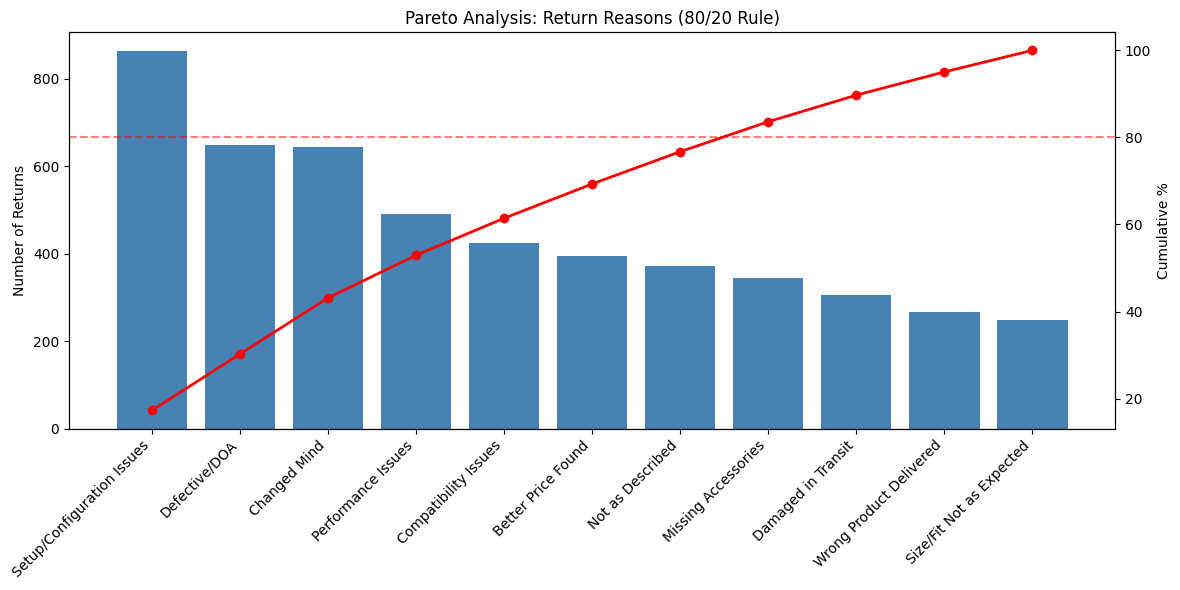

✅ Pareto chart created!


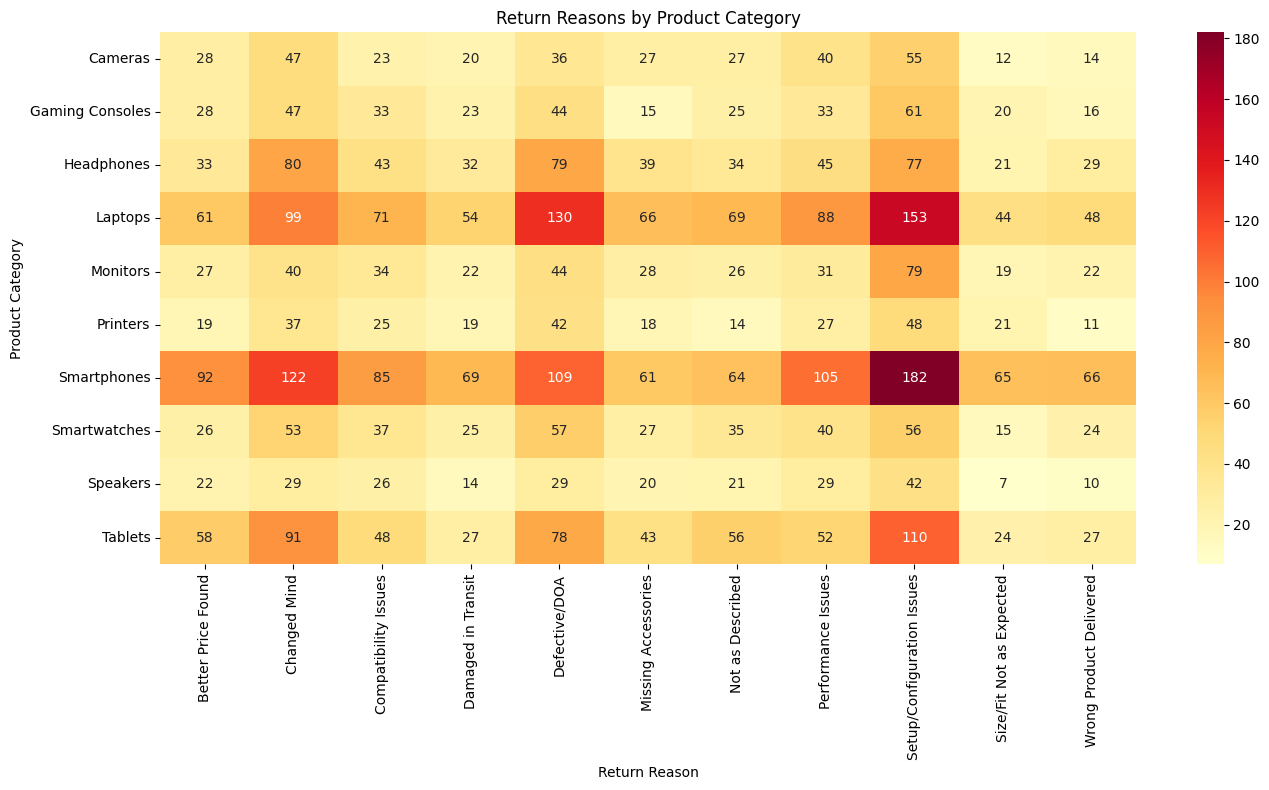

✅ Heatmap created!

--- Support vs No-Support Outcomes ---
                   Total_Returns  Avoidable_Returns  Returns_Prevented  Avg_CSAT  Avg_Price
No Support                  2717               1025                  0      2.42   56113.17
Contacted Support           2283               1247                328      3.05   54033.17

--- Which Return Reasons Are Most Avoidable? ---
                            Total  Avoidable  Avoidable_%
Return_Reason                                            
Setup/Configuration Issues    863        741         85.9
Compatibility Issues          425        292         68.7
Performance Issues            490        328         66.9
Missing Accessories           344        220         64.0
Size/Fit Not as Expected      248        114         46.0
Not as Described              371        158         42.6
Changed Mind                  645        257         39.8
Better Price Found            394        108         27.4
Wrong Product Delivered       267  

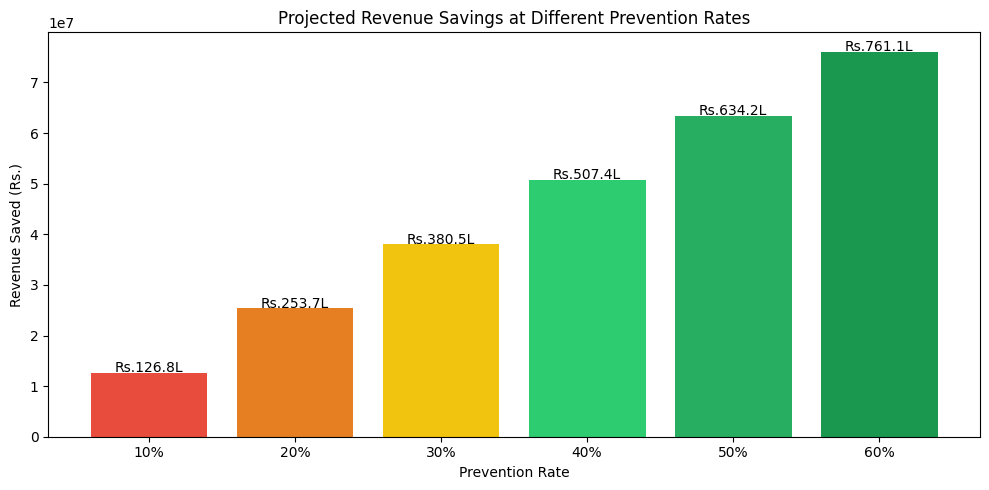

In [6]:
# NOTEBOOK 03: ROOT CAUSE ANALYSIS + RECOMMENDATIONS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ===== PART 1: ROOT CAUSE ANALYSIS =====

# Load Data
df = pd.read_excel('returns_dataset (1).xlsx', sheet_name='Returns_Data')
df['Support_Channel'] = df['Support_Channel'].fillna('No Support Contacted')
print("✅ Data loaded for Root Cause Analysis")

# Pareto Chart
reason_counts = df['Return_Reason'].value_counts()
cumulative_pct = reason_counts.cumsum() / reason_counts.sum() * 100

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(range(len(reason_counts)), reason_counts.values, color='steelblue')
ax1.set_xticks(range(len(reason_counts)))
ax1.set_xticklabels(reason_counts.index, rotation=45, ha='right')
ax1.set_ylabel('Number of Returns')

ax2 = ax1.twinx()
ax2.plot(range(len(cumulative_pct)), cumulative_pct.values, 'ro-', linewidth=2)
ax2.axhline(y=80, color='red', linestyle='--', alpha=0.5)
ax2.set_ylabel('Cumulative %')

plt.title('Pareto Analysis: Return Reasons (80/20 Rule)')
plt.tight_layout()
plt.show()
print("✅ Pareto chart created!")

# Heatmap
cross_tab = pd.crosstab(df['Product_Category'], df['Return_Reason'])
plt.figure(figsize=(14, 8))
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Return Reasons by Product Category')
plt.xlabel('Return Reason')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()
print("✅ Heatmap created!")

# Support vs No-Support Outcomes
support_analysis = df.groupby('Customer_Contacted_Support').agg(
    Total_Returns=('Order_ID', 'count'),
    Avoidable_Returns=('Is_Avoidable_Return', 'sum'),
    Returns_Prevented=('Return_Prevented', 'sum'),
    Avg_CSAT=('CSAT_Score', 'mean'),
    Avg_Price=('Product_Price_INR', 'mean')
).round(2)

support_analysis.index = ['No Support', 'Contacted Support']
print("\n--- Support vs No-Support Outcomes ---")
print(support_analysis.to_string())

# Avoidable Return Rate by Reason
avoidable_by_reason = df.groupby('Return_Reason').agg(
    Total=('Order_ID', 'count'),
    Avoidable=('Is_Avoidable_Return', 'sum')
).round(2)

avoidable_by_reason['Avoidable_%'] = (avoidable_by_reason['Avoidable'] / avoidable_by_reason['Total'] * 100).round(1)
avoidable_by_reason = avoidable_by_reason.sort_values('Avoidable_%', ascending=False)

print("\n--- Which Return Reasons Are Most Avoidable? ---")
print(avoidable_by_reason.to_string())

# ===== PART 2: RECOMMENDATIONS & COST SAVINGS =====

print("\n" + "=" * 60)
print("   COST SAVINGS PROJECTIONS")
print("=" * 60)

total_returns = len(df)
avoidable = df[df['Is_Avoidable_Return'] == 1]
avoidable_count = len(avoidable)
avoidable_revenue = avoidable['Product_Price_INR'].sum()

already_prevented = df['Return_Prevented'].sum()
current_prevention_rate = already_prevented / avoidable_count * 100

scenarios = [25, 40, 60]

print("")
print(f"   Avoidable Returns:     {avoidable_count}")
print(f"   Revenue at Risk:       Rs.{avoidable_revenue:,.0f}")
print(f"   Current Prevention:    {current_prevention_rate:.1f}%")
print("")
print("   --- What If We Improve? ---")
print("")

for rate in scenarios:
    prevented_count = int(avoidable_count * rate / 100)
    saved = avoidable_revenue * rate / 100
    print(f"   At {rate}% prevention: {prevented_count} returns saved = Rs.{saved:,.0f} saved")

print("=" * 60)

# Priority Action Matrix
actions = df.groupby('Return_Reason').agg(
    Total=('Order_ID', 'count'),
    Avoidable=('Is_Avoidable_Return', 'sum'),
    Revenue_At_Risk=('Product_Price_INR', 'sum'),
    Support_Contact_Rate=('Customer_Contacted_Support', 'mean')
).round(2)

actions['Avoidable_%'] = (actions['Avoidable'] / actions['Total'] * 100).round(1)
actions['Support_Contact_%'] = (actions['Support_Contact_Rate'] * 100).round(1)
actions = actions.drop(columns=['Support_Contact_Rate'])
actions = actions.sort_values('Revenue_At_Risk', ascending=False)

print("\n--- PRIORITY ACTION MATRIX ---")
print("(Focus on: High Avoidable% + Low Support Contact% = Biggest Opportunity)")
print("")
print(actions.to_string())

# Savings Chart
rates = [10, 20, 30, 40, 50, 60]
savings = [avoidable_revenue * r / 100 for r in rates]

plt.figure(figsize=(10, 5))
bars = plt.bar(range(len(rates)), savings, color=['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60', '#1a9850'])
plt.xticks(range(len(rates)), [f'{r}%' for r in rates])
plt.xlabel('Prevention Rate')
plt.ylabel('Revenue Saved (Rs.)')
plt.title('Projected Revenue Savings at Different Prevention Rates')

for bar, s in zip(bars, savings):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100000,
             f'Rs.{s/100000:.1f}L', ha='center', fontsize=10)

plt.tight_layout()
plt.show()
